# Isolation Forest at work: pros and cons
**Data Centric AI – Outlier detection** · Master Degree in Computer Science

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/iForest_outlier_detection.ipynb)

This notebook shows the **Isolation Forest** (slides *Isolation Forest* and *iForest Subsampling*): outliers are isolated by random axis-parallel splits in fewer steps than normal points, and the anomaly score is

$$s(x,n)=2^{-\frac{E(h(x))}{c(n)}}$$

where $E(h(x))$ is the average path length over the trees and $c(n)$ the average path length of an unsuccessful search in a binary tree built on n points.

We will see:
1. iForest on the dataset shared with kNN, density and LOF (global vs local outliers);
2. the effect of **subsampling** on clustered anomalies (masking) and on small normal clusters (swamping);
3. **scalability** compared with LOF;
4. the bias of **axis-parallel splits** on a curved manifold (the autoencoder example).

Runs on CPU in about one minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import roc_auc_score
import pandas as pd

def make_dataset(seed=0):
    """2-D dataset shared by the kNN, density, LOF and iForest examples."""
    rng = np.random.default_rng(seed)
    A = rng.normal([0, 0], 0.2, (300, 2))          # dense cluster
    B = rng.normal([6, 0], 1.2, (200, 2))          # sparse cluster
    C = rng.normal([2.5, 5.0], 0.15, (10, 2))      # small, but NORMAL, cluster
    glob = np.array([[-4., -4.], [3., -5.], [11., 5.], [10., -5.]])   # global outliers
    grp  = rng.normal([-3.5, 3.0], 0.08, (5, 2))   # group of outliers (micro-cluster)
    ang  = np.array([0.3, 1.9, 3.4, 4.9])
    loc  = np.c_[1.3*np.cos(ang), 1.3*np.sin(ang)] # local outliers close to A
    X = np.vstack([A, B, C, glob, grp, loc])
    kind = np.array(['A']*300 + ['B']*200 + ['C']*10 + ['global']*4 + ['group']*5 + ['local']*4)
    y = np.isin(kind, ['global', 'group', 'local']).astype(int)   # 1 = outlier (used ONLY to evaluate)
    return X, y, kind

X, y, kind = make_dataset()
N_OUT = int(y.sum())                 # 13 outliers out of 523 points
TYPES = ['global', 'group', 'local', 'A', 'B', 'C']
print(X.shape, '-', N_OUT, 'outliers')
pd.Series(kind).value_counts().reindex(TYPES).to_frame('points').T

(523, 2) - 13 outliers


,global,group,local,A,B,C
points,4,5,4,300,200,10


In [2]:
NORM_C, OUT_C, FP_C = '#4C78A8', '#C0392B', '#E67E22'

def top_n(score, n=N_OUT):
    """Unsupervised labelling: the n points with the highest anomaly score are outliers."""
    flag = np.zeros(len(score), bool)
    flag[np.argsort(-score)[:n]] = True
    return flag

def evaluate(score, name='', n=N_OUT):
    """Ground truth is used only here, to assess the result."""
    f = top_n(score, n)
    row = {'ROC AUC': round(roc_auc_score(y, score), 3), 'P@n': round(y[f].mean(), 2)}
    row.update({f'{t} flagged': int(f[kind == t].sum()) for t in TYPES})
    return pd.DataFrame(row, index=[name])

def detect_plot(ax, score, title='', n=N_OUT):
    f = top_n(score, n)
    tp, fp, fn = f & (y == 1), f & (y == 0), ~f & (y == 1)
    ax.scatter(*X[(y == 0) & ~fp].T, s=12, c=NORM_C, alpha=.45, lw=0, label='normal')
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'detected outliers TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'missed outliers FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=60, c=FP_C, edgecolors='k', lw=.5, label=f'false alarms FP ({fp.sum()})')
    ax.set_title(title); ax.set_aspect('equal')
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

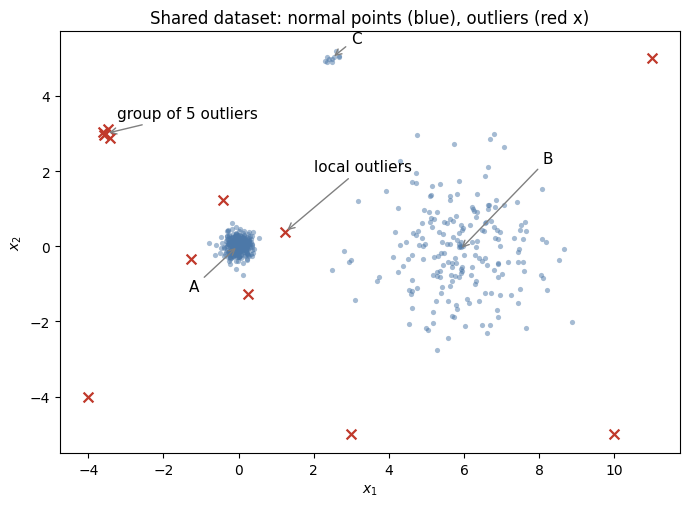

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
style = {'A': (NORM_C, 'o'), 'B': (NORM_C, 'o'), 'C': (NORM_C, 'o'),
         'global': (OUT_C, 'x'), 'group': (OUT_C, 'x'), 'local': (OUT_C, 'x')}
for t, (c, m) in style.items():
    ax.scatter(*X[kind == t].T, s=14 if m == 'o' else 50, c=c, marker=m, alpha=.5 if m == 'o' else 1, lw=1.6 if m == 'x' else 0)
for t, (dx, dy) in {'A': (-1.3, -1.2), 'B': (2.2, 2.3), 'C': (0.5, 0.4), 'group': (0.3, 0.4)}.items():
    cx, cy = X[kind == t].mean(axis=0)
    ax.annotate(t if t != 'group' else 'group of 5 outliers', (cx, cy), (cx + dx, cy + dy), fontsize=11,
                arrowprops=dict(arrowstyle='->', color='gray'))
ax.annotate('local outliers', (1.24, 0.38), (2.0, 2.0), fontsize=11, arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('Shared dataset: normal points (blue), outliers (red x)'); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); plt.show()

## 1. iForest on the shared dataset
Default settings: 100 → here 300 trees, subsample size ψ = 256, tree height limit ⌈log₂ ψ⌉ = 8.

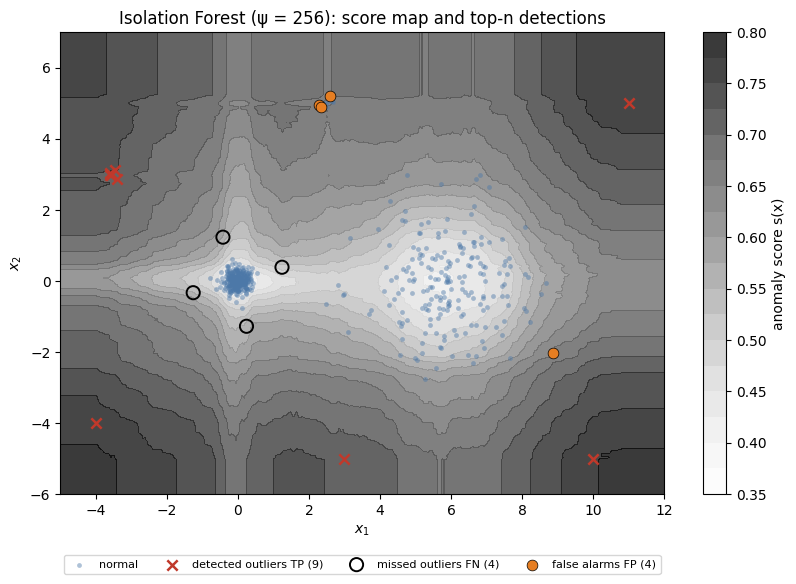

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
iForest psi=256,0.979,0.69,4,5,0,0,1,3


In [4]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=300, max_samples=256, random_state=0).fit(X)
s_if = -iso.score_samples(X)          # = s(x, n) in [0, 1]: close to 1 -> outlier

# score map on a grid
gx, gy = np.meshgrid(np.linspace(-5, 12, 300), np.linspace(-6, 7, 230))
G = -iso.score_samples(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(10, 6))
cs = ax.contourf(gx, gy, G, levels=20, cmap='Greys', alpha=.8); plt.colorbar(cs, label='anomaly score s(x)')
detect_plot(ax, s_if, 'Isolation Forest (ψ = 256): score map and top-n detections')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4); plt.show()
evaluate(s_if, 'iForest psi=256')

* Global outliers and the group are found (with ψ = 256 the group is rarely sampled entirely, so it is easy to isolate).
* The **local outliers are missed**: the splits are random and global, and the region around A is "small" compared with the whole space, so a local outlier is isolated only slightly earlier than the points on the border of A.
* The score map shows **rectangular, axis-aligned** patterns: a consequence of axis-parallel splits.

In [5]:
def knn_score(X, k):
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return d[:, 1:].mean(axis=1)
lof = -LocalOutlierFactor(n_neighbors=10).fit(X).negative_outlier_factor_
pd.concat([evaluate(knn_score(X, 10), 'kNN distance k=10'), evaluate(-1 / knn_score(X, 10), 'density k=10'),
           evaluate(lof, 'LOF k=10'), evaluate(s_if, 'iForest psi=256')])

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN distance k=10,0.989,0.69,4,5,0,0,4,0
density k=10,0.989,0.69,4,5,0,0,4,0
LOF k=10,1.000,1.00,4,5,4,0,0,0
iForest psi=256,0.979,0.69,4,5,0,0,1,3


## 2. Subsampling and masking of clustered anomalies
Setting similar to the slides (Liu et al.): 4000 normal points and two **dense clusters of 50 anomalies** each, close to the normal data. With large samples the anomaly clusters are dense and need many splits to be isolated (masking); with small samples each tree sees only a few anomalies, which are isolated quickly.

,P@100 mean,P@100 std
psi,,
16,0.99,0.01
32,1.00,0.01
64,1.00,0.00
128,0.99,0.01
256,0.96,0.02
512,0.81,0.03
1024,0.64,0.03
2048,0.46,0.02
4100,0.33,0.01


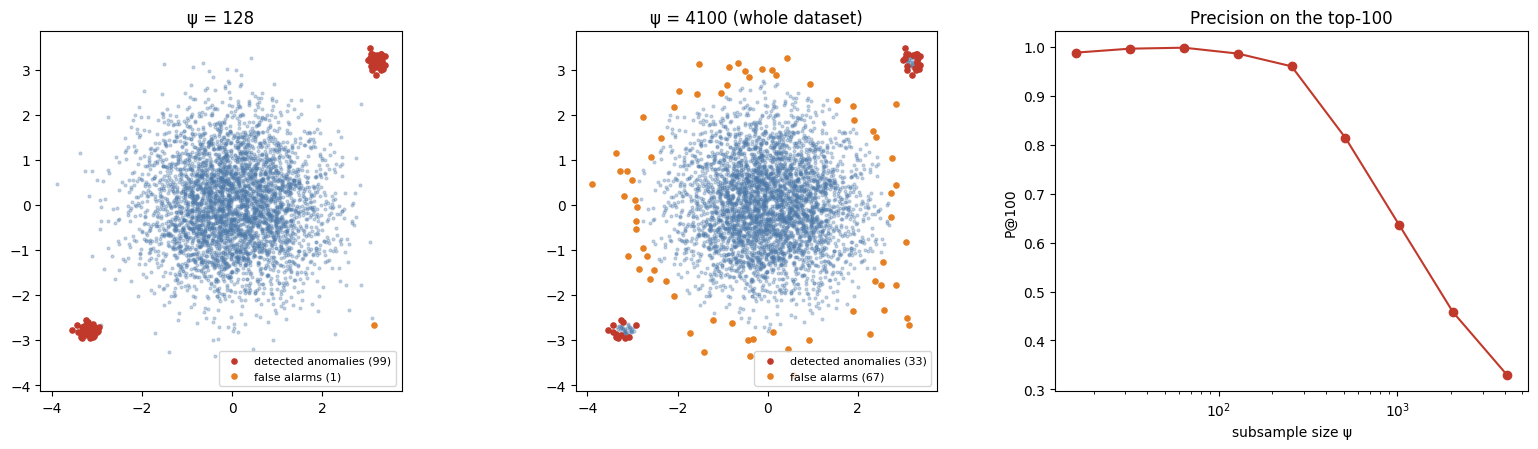

In [6]:
rng = np.random.default_rng(0)
Xs = np.vstack([rng.normal(0, 1, (4000, 2)), rng.normal([3.2, 3.2], 0.12, (50, 2)), rng.normal([-3.2, -2.8], 0.12, (50, 2))])
ys = np.r_[np.zeros(4000), np.ones(100)]

rows = []
for psi in [16, 32, 64, 128, 256, 512, 1024, 2048, 4100]:
    p = []
    for seed in range(5):
        s = -IsolationForest(n_estimators=200, max_samples=psi, random_state=seed).fit(Xs).score_samples(Xs)
        p.append(ys[np.argsort(-s)[:100]].mean())
    rows.append({'psi': psi, 'P@100 mean': np.mean(p), 'P@100 std': np.std(p)})
sub = pd.DataFrame(rows).set_index('psi'); display(sub.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, psi in zip(axes[:2], [128, 4100]):
    s = -IsolationForest(n_estimators=200, max_samples=psi, random_state=0).fit(Xs).score_samples(Xs)
    f = np.zeros(len(s), bool); f[np.argsort(-s)[:100]] = True
    ax.scatter(*Xs[~f].T, s=4, c=NORM_C, alpha=.3)
    ax.scatter(*Xs[f & (ys == 1)].T, s=14, c=OUT_C, label=f'detected anomalies ({(f & (ys == 1)).sum()})')
    ax.scatter(*Xs[f & (ys == 0)].T, s=14, c=FP_C, label=f'false alarms ({(f & (ys == 0)).sum()})')
    ax.set_title(f'ψ = {psi}' + (' (whole dataset)' if psi > 4000 else '')); ax.set_aspect('equal'); ax.legend(fontsize=8, loc='lower right')
axes[2].semilogx(sub.index, sub['P@100 mean'], 'o-', c=OUT_C); axes[2].set_xlabel('subsample size ψ'); axes[2].set_ylabel('P@100')
axes[2].set_title('Precision on the top-100'); plt.tight_layout(); plt.show()

## 3. ... but too small samples can swamp small normal clusters
On the shared dataset, the small normal cluster C contains 10 of 523 points: with ψ = 32 most trees see at most one point of C, which then looks isolated.

In [7]:
pd.concat([evaluate(-IsolationForest(n_estimators=300, max_samples=psi, random_state=0).fit(X).score_samples(X), f'psi={psi}')
           for psi in [32, 64, 128, 256]])

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
psi=32,0.911,0.23,2,1,0,0,0,10
psi=64,0.937,0.23,2,1,0,0,0,10
psi=128,0.960,0.62,3,5,0,0,0,5
psi=256,0.979,0.69,4,5,0,0,1,3


ψ is therefore a trade-off: small enough to avoid masking of clustered anomalies, large enough to represent the small normal groups.

## 4. Scalability
iForest builds each tree on ψ points (independent of N) and scores a point in O(t·log ψ): the cost is **linear in N**, and no distance is computed.

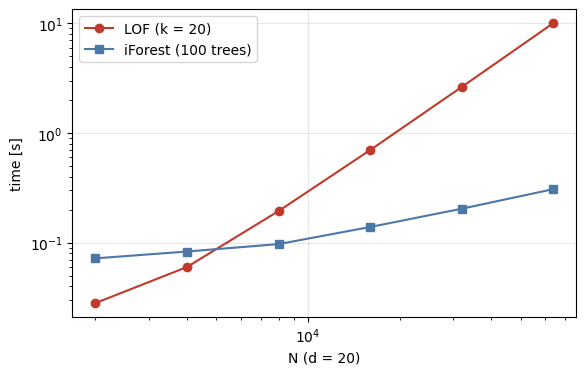

,2000,4000,8000,16000,32000,64000
LOF [s],0.03,0.06,0.19,0.70,2.63,10.04
iForest [s],0.07,0.08,0.10,0.14,0.20,0.31


In [8]:
import time
rng = np.random.default_rng(0)
Ns, t_lof, t_if = [2000, 4000, 8000, 16000, 32000, 64000], [], []
for n in Ns:
    Z = rng.normal(size=(n, 20))
    t0 = time.time(); LocalOutlierFactor(n_neighbors=20).fit(Z); t_lof.append(time.time() - t0)
    t0 = time.time(); IsolationForest(n_estimators=100, random_state=0).fit(Z).score_samples(Z); t_if.append(time.time() - t0)
plt.figure(figsize=(6.5, 4))
plt.loglog(Ns, t_lof, 'o-', c=OUT_C, label='LOF (k = 20)'); plt.loglog(Ns, t_if, 's-', c=NORM_C, label='iForest (100 trees)')
plt.xlabel('N (d = 20)'); plt.ylabel('time [s]'); plt.legend(); plt.grid(alpha=.3); plt.show()
pd.DataFrame({'LOF [s]': t_lof, 'iForest [s]': t_if}, index=Ns).round(2).T

## 5. Axis-parallel splits on a curved manifold
We reuse the dataset of the autoencoder example: normal points along the curve x₂ = 1.5 sin(x₁) + noise, 40 outliers far from the band but inside the range of each feature. Semi-supervised protocol: training on 700 normal points, test on 300 normal + 40 outliers, threshold = 99th percentile of the training scores.

ROC AUC = 0.974   recall = 0.68   false alarms = 10


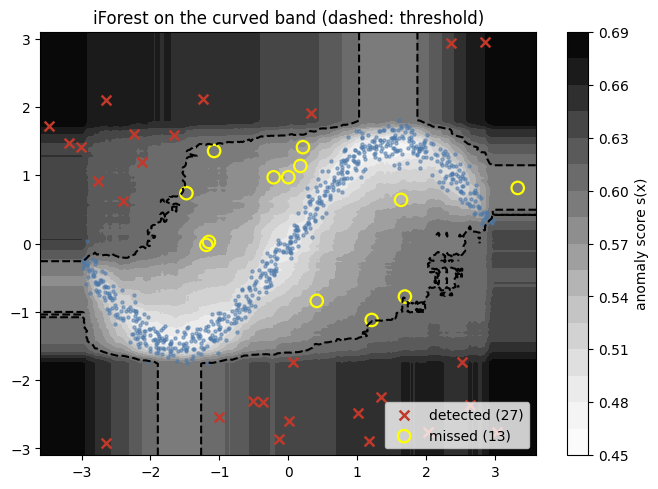

In [9]:
rng = np.random.default_rng(7)
x1 = rng.uniform(-3, 3, 1000); Xn = np.c_[x1, 1.5 * np.sin(x1) + rng.normal(0, 0.15, 1000)]
out = []
while len(out) < 40:
    p = np.array([rng.uniform(-3.5, 3.5), rng.uniform(-3, 3)])
    if abs(p[1] - 1.5 * np.sin(p[0])) > 0.8: out.append(p)
perm = rng.permutation(1000)
X_train, X_test = Xn[perm[:700]], np.vstack([Xn[perm[700:]], out]); y_test = np.r_[np.zeros(300), np.ones(40)]

iso2 = IsolationForest(n_estimators=300, random_state=0).fit(X_train)
s_tr, s_te = -iso2.score_samples(X_train), -iso2.score_samples(X_test)
t = np.percentile(s_tr, 99); pred = s_te > t
print(f'ROC AUC = {roc_auc_score(y_test, s_te):.3f}   recall = {pred[y_test == 1].mean():.2f}   false alarms = {pred[y_test == 0].sum()}')

gx, gy = np.meshgrid(np.linspace(-3.6, 3.6, 300), np.linspace(-3.1, 3.1, 260))
G = -iso2.score_samples(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 5.5))
cs = ax.contourf(gx, gy, G, levels=20, cmap='Greys'); plt.colorbar(cs, label='anomaly score s(x)')
ax.contour(gx, gy, G, levels=[t], colors='k', linestyles='--')
ax.scatter(*X_train.T, s=5, c=NORM_C, alpha=.5)
o = X_test[y_test == 1]; d = pred[y_test == 1]
ax.scatter(*o[d].T, marker='x', c=OUT_C, s=50, lw=1.8, label=f'detected ({d.sum()})')
ax.scatter(*o[~d].T, facecolors='none', edgecolors='yellow', s=80, lw=1.6, label=f'missed ({(~d).sum()})')
ax.legend(loc='lower right'); ax.set_title('iForest on the curved band (dashed: threshold)'); plt.show()

Outliers lying **inside the concavities of the curve** fall in boxes that also contain normal points along both axes: random axis-parallel splits isolate them late. The autoencoder learns the curve and detects all 40 outliers on the same data (see `Autoencoder_outlier_detection.ipynb`). Variants such as the *Extended Isolation Forest* use random oblique splits to reduce this bias.

## Takeaways
**Pros**
* **Fast and scalable**: linear in N, small memory footprint, no distance computation.
* Works well for **global** and, thanks to subsampling, for **clustered** anomalies.
* Few parameters with robust defaults (t = 100, ψ = 256); score in [0, 1] with an intuitive reading (≈ 0.5 normal, → 1 outlier).

**Cons**
* **Misses local outliers** near dense clusters (here 0/4, P@n = 0.69 vs 1.00 for LOF).
* **Axis-parallel bias**: rectangular artefacts and poor results on curved/correlated manifolds.
* ψ is a trade-off: too large → masking of anomaly clusters; too small → swamping of small normal clusters.
* Randomized: scores vary with the seed (use enough trees).